In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not on colab')

Mounted at /content/drive


# Movie Recommender System using MovieLens data (EDA)
Author: Michael Fitiavana Randriamifidy

Created: 26 December 2025

Last Updated: 28 December 2025

In [ ]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

In [ ]:
DATA_SIZE_DICT= {
    0: "ml-latest-small",
    1: "ml-25m ",
    2: "ml-32m",
}
DATA_SIZE_STR = DATA_SIZE_DICT[2]

# Setting up

In [ ]:
import importlib
sys.modules["imp"] = importlib
%load_ext autoreload
%reload_ext autoreload
%autoreload 2

## Setting up Notebooks

In [ ]:
from typing import Optional, Callable, Dict, Any, List

def download_and_extract_movielens(
                            data_folders:List[str],
                            extracted_data_folder:str='./data',
                            data_size_str:str='ml-latest-small',
                            only_extract:bool=True
                            ):
    pattern = re.compile(rf"{data_size_str}\.zip$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(p.name)]
        if matches:
            print("Found zip file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip")
        !curl -C - -O --output-dir "{data_folder}" "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip"
    print(f"Extract to {extracted_data_folder}")
    !unzip -n "{data_folder}/{data_size_str}.zip" -d "{extracted_data_folder}"


    pattern = re.compile(rf"{data_size_str}\.zip.md5$")
    for data_folder in data_folders:
        matches = [p for p in Path(data_folder).iterdir() if pattern.match(str(p))]
        if matches:
            print("Found zip.md5 file(s):", str(matches[-1]))
            break
    if not  matches:
        print(f"Downloading:{data_size_str}.zip.md5 from https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5")
        !curl -C - -O --output-dir "{data_folder}"  "https://files.grouplens.org/datasets/movielens/{data_size_str}.zip.md5"

def is_kaggle() -> bool:
    """
    Detect if the code is running on Kaggle.

    Returns:
        bool: True if running on Kaggle, False otherwise.
    """
    return "KAGGLE_URL_BASE" in os.environ


def is_colab() -> bool:
    """
    Detect if the code is running on Google Colab.

    Returns:
        bool: True if running on Google Colab, False otherwise.
    """
    try:
        import google.colab
        return True
    except ImportError:
        return False


def set_project(
    fun_todo_kaggle: Optional[Callable[..., Any]] = None,
    fun_todo_colab: Optional[Callable[..., Any]] = None,
    fun_todo_local: Optional[Callable[..., Any]] = None,
    kwargs_kaggle: Optional[Dict[str, Any]] = None,
    kwargs_colab: Optional[Dict[str, Any]] = None,
    kwargs_local: Optional[Dict[str, Any]] = None
) -> Optional[Any]:
    """
    Execute platform-specific setup functions based on the current environment.

    This function detects whether code is running on Kaggle, Google Colab, or locally,
    and executes the corresponding setup function with the provided keyword arguments.

    Args:
        fun_todo_kaggle: Optional function to execute on Kaggle.
        fun_todo_colab: Optional function to execute on Google Colab.
        fun_todo_local: Optional function to execute locally.
        kwargs_kaggle: Keyword arguments to pass to the Kaggle function.
        kwargs_colab: Keyword arguments to pass to the Colab function.
        kwargs_local: Keyword arguments to pass to the local function.

    Returns:
        The return value of the executed function, or None if no function is provided
        for the detected environment.
    """
    # Initialize kwargs dictionaries if None
    kwargs_kaggle = kwargs_kaggle or {}
    kwargs_colab = kwargs_colab or {}
    kwargs_local = kwargs_local or {}

    # Conditional commands
    if is_kaggle():
        print("Running on Kaggle")
        if fun_todo_kaggle is not None:
            return fun_todo_kaggle(**kwargs_kaggle)
    elif is_colab():
        print("Running on Google Colab")
        if fun_todo_colab is not None:
            return fun_todo_colab(**kwargs_colab)
    else:
        print("Running locally")
        if fun_todo_local is not None:
            return fun_todo_local(**kwargs_local)

    return None

def is_drive_mounted():
    return os.path.exists("/content/drive/MyDrive")


def fun_todo_kaggle(**kwargs):
    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(f"/kaggle/working/movie-recommender-system-{data_size_str}")
    PROJECT_PATH = Path("/kaggle/temp/")
    DATA_FOLDER = PROJECT_PATH / "download/data"
    EXTRACTED_DATA_FOLDER = Path("/kaggle/input/movielens-dataset/")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_colab(**kwargs):
    if is_drive_mounted():
        print("Google Drive is already mounted")
    else:
        raise "Mount Drive"

    data_size_str = kwargs['data_size_str'] if "data_size_str" in kwargs else "latest-small"
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    # os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20

    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)
    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER

def fun_todo_local(**kwargs):
    data_size_str = kwargs.get('data_size_str', 'latest-small')
    project_dir_abs = kwargs.get("project_dir_abs", Path.cwd())
    os.chdir(project_dir_abs)
    REMOTE_PROJECT_PATH = Path(project_dir_abs) / f"working/movie-recommender-system-{data_size_str}"
    PROJECT_PATH =  Path(project_dir_abs) / f"temp/movie-recommender-system-{data_size_str}"
    DATA_FOLDER = Path("./downloads/data")
    EXTRACTED_DATA_FOLDER = Path("./data")
    PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    EXTRACTED_DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    REMOTE_PROJECT_PATH.mkdir(exist_ok=True, parents=True)
    DATA_FOLDER.mkdir(exist_ok=True, parents=True)
    !pwd
    !ls $REMOTE_PROJECT_PATH -R | head -20
    if project_dir_abs.as_posix() not in sys.path:
        sys.path.append(project_dir_abs.as_posix())
    print(sys.path)

    download_and_extract_movielens(
        [DATA_FOLDER, project_dir_abs / DATA_FOLDER],
        EXTRACTED_DATA_FOLDER,
        data_size_str = DATA_SIZE_STR)
    return REMOTE_PROJECT_PATH, PROJECT_PATH, DATA_FOLDER, EXTRACTED_DATA_FOLDER


In [ ]:
if Path.cwd().name == "notebooks":
    PROJECT_DIR_ABS = Path.cwd().parent
else:
    PROJECT_DIR_ABS = Path.cwd()
print(f"MovieLens data:{DATA_SIZE_STR}")
kwargs = {"data_size_str":DATA_SIZE_STR}
kwargs_kaggle = {**kwargs, **{'project_dir_abs':Path(f"/kaggle/input/movie-recommender-system-{DATA_SIZE_STR}")}}
kwargs_colab = {**kwargs, **{'project_dir_abs':Path(f"/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system")}}
kwargs_local = {**kwargs, **{'project_dir_abs':PROJECT_DIR_ABS}}
(
    REMOTE_PROJECT_PATH,
    PROJECT_PATH,
    DATA_FOLDER,
    EXTRACTED_DATA_FOLDER
    ) = set_project(fun_todo_kaggle,
                    fun_todo_colab,
                    fun_todo_local,
                    kwargs_kaggle=kwargs_kaggle,
                    kwargs_colab=kwargs_colab,
                    kwargs_local=kwargs_local)

ratings_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "ratings.csv"
movies_path = EXTRACTED_DATA_FOLDER / DATA_SIZE_STR / "movies.csv"
PLOT_FOLDER = PROJECT_PATH / "plots"
MODEL_FOLDER = PROJECT_PATH / "models"

MovieLens data:ml-32m
Running on Google Colab
Google Drive is already mounted
/content
/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m:
models

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models:
bias_only
with_embeddings
with_features

/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/working/movie-recommender-system-ml-32m/models/bias_only:
ml-32m-als-K02-iter50-lambda1-tau0.1-bias_only-latest.joblib
ml-32m-als-K02-iter50-lambda1-tau10-bias_only-latest.joblib
ml-32m-als-K02-iter50-lambda1-tau1-bias_only-latest.joblib
ml-32m-als-K04-iter50-lambda1-tau0.1-bias_only-latest.joblib
ml-32m-als-K04-iter50-lambda1-tau10-bias_only-latest.joblib
ml-32m-als-K04-iter50-lambda1-tau1-bias_only-latest.joblib
ml-32m-als-K08-iter50-lambda1-tau0.1-bias_only-latest.joblib
ml-32m-als-K08-iter50-lambda1-tau10-bias_only-latest.joblib
ml-32m-als-K08-iter50-lambda1-tau1-bias_only-lates

## Import

In [ ]:
from recommender.data.csr import (
    get_nelements_by_row_csr,
    get_nrows_csr,
    sparsity_of_matrix_csr,
)

from recommender.data.ratings import (
    find_movie_id_by_title,
    get_id_from_idx,
    get_movie_info_from_id,
    get_movie_title_from_id,
    load_data_movie_feature_csr,
    load_movie_id_idx_mapping,
    load_ratings_and_features_data_csr,
)

from recommender.data.stats import (
    compute_csr_statistics,
    get_degree_frequency_csr,
    get_distribution_stats,
    get_power_law_from_csr,
)

from recommender.plots.plotting import (
    plot_bar_general,
    plot_feature_distribution_bar,
    plot_ratings_csr_publication,
    save_plot,
)


# Load datasets

In [ ]:
(
    user_id_to_idx, user_idx_to_id, movie_id_to_idx, movie_idx_to_id,
    feature_idx_to_id, feature_id_to_idx,
    ratings_by_user_csr, ratings_by_movie_csr,
    features_by_movie_csr, movies_by_feature_csr, movies_title
)= load_ratings_and_features_data_csr(ratings_path, movies_path)
assert get_nrows_csr(ratings_by_user_csr) == get_nrows_csr(ratings_by_user_csr)

Loading ratings:   0%|          | 0/32000204 [00:00<?, ? lines/s]

Loading features:   0%|          | 0/87585 [00:00<?, ? lines/s]

In [ ]:
(
    data_movie_id_to_idx,
    data_movie_idx_to_id,
    data_feature_id_to_idx,
    data_feature_idx_to_id,
    data_movies_title,
    movies_by_feature_csr,
    features_by_movie_csr,
    ) = load_data_movie_feature_csr(movies_path)

movie_id_to_idx, movie_idx_to_id = load_movie_id_idx_mapping(ratings_path)

Loading movies'feature:   0%|          | 0/87585 [00:00<?, ? movie/s]

Loading rated movie Id:   0%|          | 0/32000204 [00:00<?, ? ratings/s]

### Rating Matrix sparsity

In [ ]:
N = get_nrows_csr(ratings_by_movie_csr)
M = get_nrows_csr(ratings_by_user_csr)
nratings, ratings_sparsity = sparsity_of_matrix_csr(ratings_by_user_csr, (M, N))
print(f"Rating Matrix sparsity \t:{ratings_sparsity:.5f}\n" \
f"Number of ratings \t: {nratings}")

Rating Matrix sparsity 	:0.00189
Number of ratings 	: 32000204


### Power law

Users: p(d) proportional to  d^(-1.93)


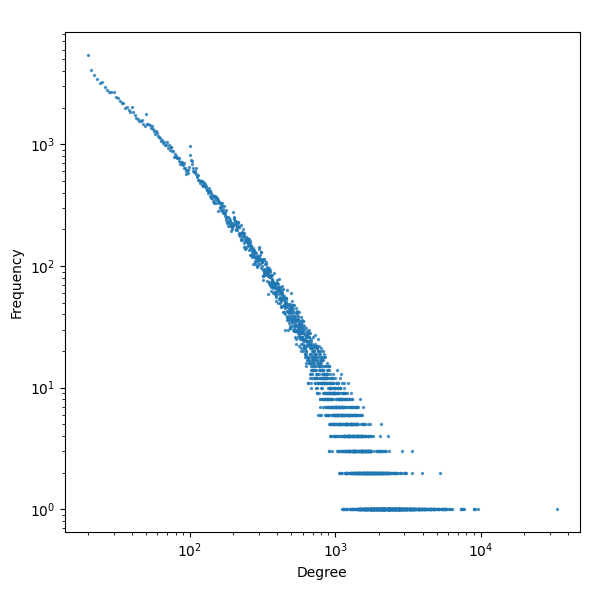

In [ ]:
# power law Users
type_vector = "Users"
title = f"Ratings: {type_vector} Degree Distribution"
title = " "
plot_folder = PLOT_FOLDER
filename = f"power-law-{type_vector}.pdf"
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)
fig, ax = plt.subplots(1, figsize=(6,6))

plot_ratings_csr_publication(ratings_by_user_csr,
                            title=title,
                            log_plot=True,
                            bw_plot=False,
                            color='C0',
                            fig_ax=(fig, ax))
save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

a, gamma = get_power_law_from_csr(ratings_by_user_csr)
print(f"{type_vector}: p(d) proportional to  d^({gamma:.2f})")

Movies: p(d) proportional to  d^(-0.62)


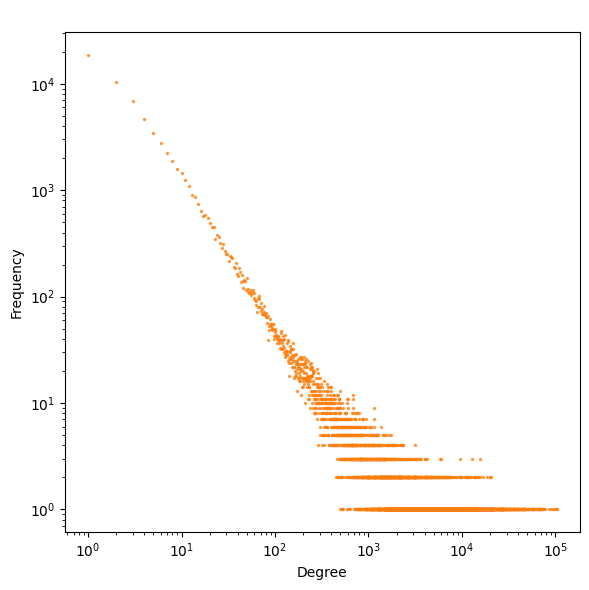

In [ ]:
# power law Movies
type_vector = "Movies"
title = f"Ratings: {type_vector} Degree Distribution"
title = " "

plot_folder = PLOT_FOLDER
filename = f"power-law-{type_vector}.pdf"
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)
fig, ax = plt.subplots(1, figsize=(6,6))

plot_ratings_csr_publication(ratings_by_movie_csr,
                            title=title,
                            log_plot=True,
                            bw_plot=False,
                            color='C1',
                            fig_ax=(fig, ax))
save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

a, gamma = get_power_law_from_csr(ratings_by_movie_csr)
print(f"{type_vector}: p(d) proportional to  d^({gamma:.2f})")

['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/ratings-distribution-filtered-Users.pdf']

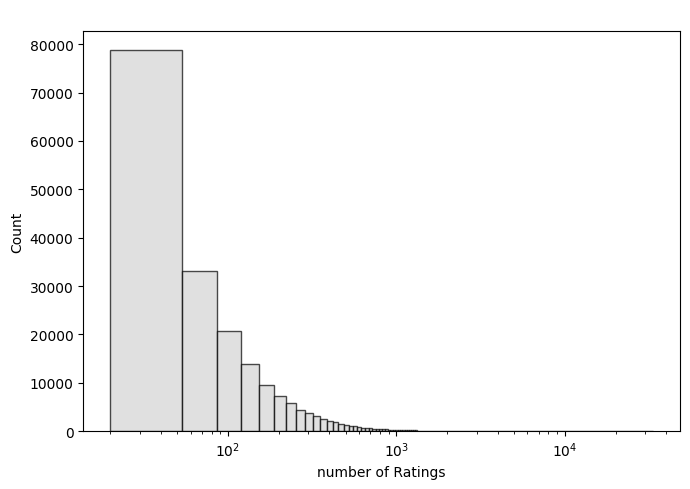

In [ ]:
type_vector = "Users"
title = f"Ratings: {type_vector} Degree Distribution"
title = " "

plot_folder = PLOT_FOLDER
filename = f"ratings-distribution-filtered-{type_vector}.pdf"
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

# bins= [0, 10**2, 200 , 300, 400, 500, 600, 700,  800, 900, 10**3, 10**4, np.inf]
bins = 10**3

plot_ratings_csr_publication(ratings_by_user_csr,
                            title=title,
                            log_plot=True,
                            bw_plot=True,
                            color='C0',
                            hist=True,
                            bins= bins
                            )
save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/ratings-distribution-filtered-Movies.pdf']

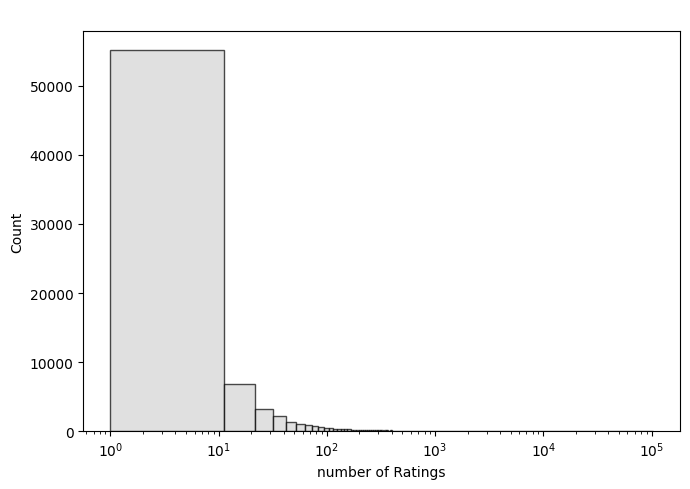

In [ ]:
type_vector = "Movies"
title = f"Ratings: {type_vector} Degree Distribution"
title = " "
bins = 10**4

plot_folder = PLOT_FOLDER
filename = f"ratings-distribution-filtered-{type_vector}.pdf"
plot_filepath = plot_folder / filename
plot_filepath = str(plot_filepath)

plot_ratings_csr_publication(ratings_by_movie_csr,
                            title=title,
                            log_plot=True,
                            bw_plot=True,
                            color='C0',
                            hist=True,
                            bins= bins
                            )
save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

### Search Movie by title

In [ ]:
title = "Lord"
ids, titles = find_movie_id_by_title(title, movies_title, movie_idx_to_id, movie_id_to_idx)
results = get_movie_info_from_id(
    ids,
    movie_id_to_idx,
    feature_idx_to_id,
    movies_title,
    features_by_movie_csr
    )
pd.DataFrame(results)

,id,title,features
0,4993,"Lord of the Rings: The Fellowship of the Ring,...",[Comedy]
1,33672,Lords of Dogtown (2005),"[Comedy, Romance]"
2,5952,"Lord of the Rings: The Two Towers, The (2002)",[Documentary]
3,7153,"Lord of the Rings: The Return of the King, The...",[Drama]
4,36529,Lord of War (2005),[Drama]
5,2116,"Lord of the Rings, The (1978)","[Drama, Thriller]"
6,3461,Lord of the Flies (1963),"[Crime, Drama, Thriller]"
7,4951,Lord of the Flies (1990),"[Adventure, Comedy, Thriller]"
8,177,Lord of Illusions (1995),"[Action, Comedy, Crime, Drama]"
9,6991,"Greystoke: The Legend of Tarzan, Lord of the A...","[Comedy, Drama]"


# EDA

In [ ]:
_ = compute_csr_statistics(
    features_by_movie_csr,
    movies_by_feature_csr,
    ratings_by_movie_csr,
    ratings_by_user_csr,
    movie_idx_to_id,
    feature_idx_to_id,
    user_idx_to_id,
    bins=[0, 10**2, 10**3, 10**4, np.inf]
)

Number of movies: 87585
Number of features: 20
Number of users: 200948

Ratings per movie:
0–100: 72241(82.48%)
100–1000: 7794(8.90%)
1000–10000: 3625(4.14%)
>10000: 772(0.88%)

Ratings per user:
0–100: 120273(59.85%)
100–1000: 77054(38.35%)
1000–10000: 3620(1.80%)
>10000: 1(0.00%)

Total ratings:32000204
features:['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy', 'Romance', 'Drama', 'Action', 'Crime', 'Thriller', 'Horror', 'Mystery', 'Sci-Fi', 'IMAX', 'Documentary', 'War', 'Musical', 'Western', 'Film-Noir', '(no genres listed)']


In [ ]:
x_degrees, y_frequencies = get_degree_frequency_csr(ratings_by_user_csr)
stats = get_distribution_stats(x_degrees, y_frequencies)

print("Ratings per user statistics:")
print(f"Mean: {stats['mean']:.2f}")
print(f"Variance: {stats['variance']:.2f}")
print(f"Skewness: {stats['skewness']:.2f}")
print(f"Kurtosis: {stats['kurtosis']:.2f}")

x_degrees, y_frequencies = get_degree_frequency_csr(ratings_by_movie_csr)
stats = get_distribution_stats(x_degrees, y_frequencies)

print("\nRatings per movie statistics:")
print(f"Mean: {stats['mean']:.2f}")
print(f"Variance: {stats['variance']:.2f}")
print(f"Skewness: {stats['skewness']:.2f}")
print(f"Kurtosis: {stats['kurtosis']:.2f}")

Ratings per user statistics:
Mean: 159.25
Variance: 79537.97
Skewness: 14.45
Kurtosis: 1037.94

Ratings per movie statistics:
Mean: 379.01
Variance: 6720664.47
Skewness: 15.62
Kurtosis: 347.41


Drama: & 34175 \\
Comedy: & 23124 \\
Thriller: & 11823 \\
Romance: & 10369 \\
Action: & 9668 \\
Documentary: & 9363 \\
Horror: & 8654 \\
(no genres listed): & 7080 \\
Crime: & 6976 \\
Adventure: & 5402 \\
Sci-Fi: & 4907 \\
Animation: & 4617 \\
Children: & 4520 \\
Mystery: & 4013 \\
Fantasy: & 3851 \\
War: & 2325 \\
Western: & 1696 \\
Musical: & 1059 \\
Film-Noir: & 353 \\
IMAX: & 195 \\


['/content/drive/MyDrive/Labs/ml_scale/movie-recommender-system/temp/movie-recommender-system-ml-32m/plots/Movie-over-Feature-Distribution.pdf']

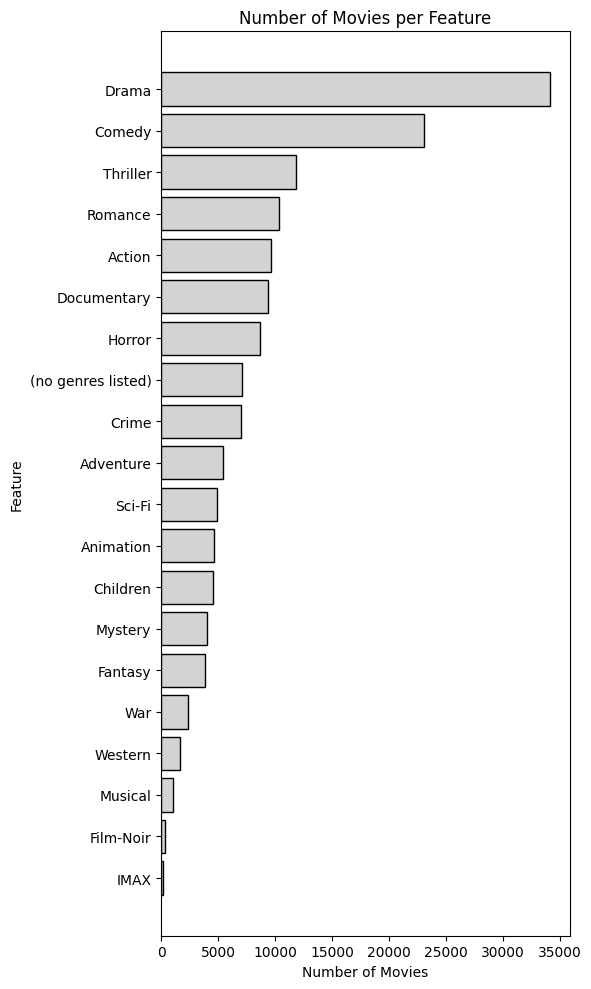

In [ ]:
filename = "Movie-over-Feature-Distribution.pdf"
plot_folder = PLOT_FOLDER
plot_filepath = plot_folder  / filename
plot_filepath = str(plot_filepath)

plot_feature_distribution_bar(movies_by_feature_csr, feature_idx_to_id, sort=True,
                            figsize=(6,10))

save_plot(
    plot_filepath,
    fig=None,
    formats="pdf",
    timestamps=False,
    use_tex=False,
    dpi=300,
    overwrite=True
)

Shawshank Redemption, The (1994): & 102929 \\
Forrest Gump (1994): & 100296 \\
Pulp Fiction (1994): & 98409 \\
Matrix, The (1999): & 93808 \\
Silence of the Lambs, The (1991): & 90330 \\
Star Wars: Episode IV - A New Hope (1977): & 85010 \\
Fight Club (1999): & 77332 \\
Jurassic Park (1993): & 75233 \\
Schindler's List (1993): & 73849 \\
Lord of the Rings: The Fellowship of the Ring, The (2001): & 73122 \\
Star Wars: Episode V - The Empire Strikes Back (1980): & 72151 \\
Braveheart (1995): & 69482 \\
Toy Story (1995): & 68997 \\
Terminator 2: Judgment Day (1991): & 68383 \\
Usual Suspects, The (1995): & 67750 \\
Star Wars: Episode VI - Return of the Jedi (1983): & 67496 \\
Lord of the Rings: The Two Towers, The (2002): & 67463 \\
Lord of the Rings: The Return of the King, The (2003): & 67449 \\
Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981): & 67408 \\
Godfather, The (1972): & 66440 \\


(<Figure size 500x900 with 1 Axes>,
 <Axes: title={'center': 'Top 20 Movies by Number of Ratings'}, xlabel='Number of Ratings', ylabel='Movie'>)

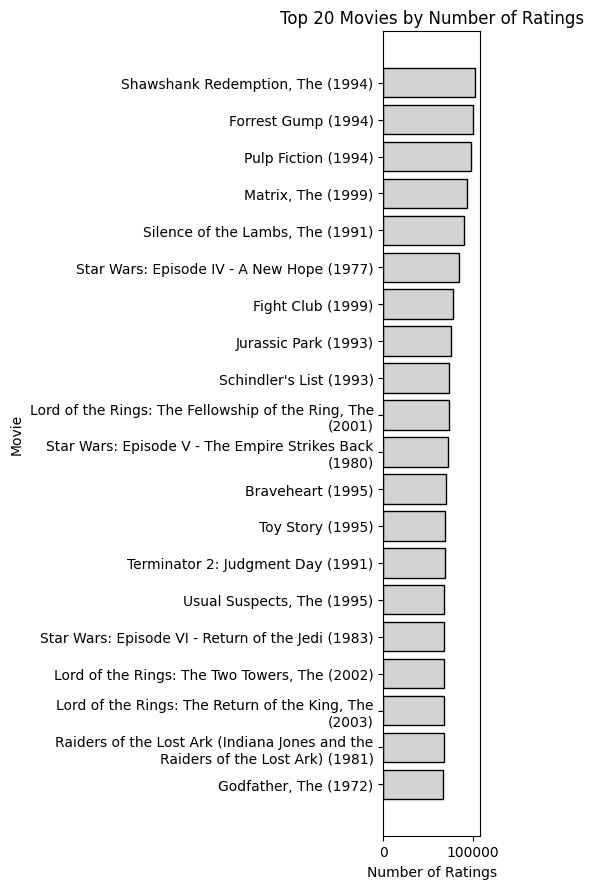

In [ ]:
degrees = get_nelements_by_row_csr(ratings_by_movie_csr)
ids = get_id_from_idx(range(len(degrees)), movie_idx_to_id)
titles = get_movie_title_from_id(ids, movie_id_to_idx, movies_title)

plot_bar_general(
    titles,
    degrees,
    topn=20,
    sort=True,
    bw_plot=True,
    # horizontal=True,
    max_label_width=50,
    max_height_per_label=100,
    horizontal=True,
    figsize=(5,9),
    rotate_xticks=90,
    xlabel="Movie",
    ylabel="Number of Ratings",
    title="Top 20 Movies by Number of Ratings"
)